# Lecture 19, Regression downscaling

> A statistical bridge from what the climate model simulates well to the rain gauge and the thermometer

Lecture 16 set out the downscaling problem and Lecture 17 gave the statistical background. This lecture works out the oldest and simplest statistical downscaling method in full, **linear regression**: the maths is derived, a synthetic station is built so that the answer is known, and the main weakness of the method is shown with numbers.

A GCM grid cell of 100 km or more cannot tell us the temperature at a station in Mandi, but the *large-scale* fields it simulates well (pressure, humidity, 850 hPa temperature) are physically linked to the local weather. If we can write the local value as a function of those fields, we can feed the GCM's future fields into the function.

By the end of this lecture you should be able to:

- explain the **perfect-prognosis** idea and the assumptions behind it;
- **derive** the least-squares estimates for simple regression (slope $=\mathrm{cov}/\mathrm{var}$) and for multiple regression ($\hat{\boldsymbol\beta}=(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf y$) by calculus;
- compute and interpret $R^2$, adjusted $R^2$, standard errors, the $t$-test on a slope, the $F$-test, and confidence versus prediction intervals;
- detect **multicollinearity** with the variance inflation factor (VIF) and say why it makes coefficients unstable;
- check the residuals, standardise predictors and test **stationarity** by calibrating and validating on different periods;
- explain why a regression-downscaled series has **too little variance and too few extremes**, derive how much, and apply two fixes.

All data in this lecture are **synthetic**, generated by a short random-number program so that the true relationships are known. The same numbers are in the companion workbook `data/downscaling/lec19/lec19_worked_examples.xlsx`, where every step of Sections 3 to 8 is a live spreadsheet formula. To use real data, replace the observations by station or IMD gridded rainfall and temperature, and the predictors by ERA5 or NCEP/NCAR reanalysis (calibration) and a CMIP6 or NEX-GDDP-CMIP6 series (application).

In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy scipy pandas matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

def read_csv(name):
    # Local copy of the repository first; on Colab fall back to the GitHub copy.
    path = f"data/downscaling/lec19/{name}"
    try:
        return pd.read_csv(path)
    except FileNotFoundError:
        return pd.read_csv("https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/" + path)

small = read_csv("lec19_small.csv")        # 15 annual values, for the hand calculation (sheet SimpleReg)
mon   = read_csv("lec19_monthly.csv")      # 70 years x 4 monsoon months, synthetic "reanalysis + station"
gcm   = read_csv("lec19_gcm_predictors.csv")  # synthetic GCM predictors, historical and future

cal = mon[mon.year <= 1990].reset_index(drop=True)   # calibration 1951-1990 (160 months)
val = mon[mon.year >  1990].reset_index(drop=True)   # validation  1991-2020 (120 months)
print(len(cal), "calibration months,", len(val), "validation months")
mon.head()

160 calibration months, 120 validation months


,year,month,slp_hPa,q_gkg,t850_C,t2m_C,tmax_C,rain_mm,z_noise
0,1951,6,0.416,-0.445,-0.559,-0.342,-1.220,74.4,-0.803
1,1951,7,-0.752,0.805,-0.131,-0.486,0.890,46.7,0.243
2,1951,8,1.047,-0.840,-1.851,-2.031,-2.953,70.5,-1.656
3,1951,9,-0.815,-0.404,-0.707,-0.954,0.517,39.0,0.656
4,1952,6,2.222,0.496,0.272,0.623,-0.376,45.6,1.143


# 1) The idea: perfect prognosis

Regression downscaling needs **three data sets**:

| Data | Role | Example |
|:--|:--|:--|
| Observed **predictand** $y$ (local) | what we want | station Tmax or monthly rainfall, IMD gridded data |
| **Predictors** $x_1,\dots,x_p$ from a **reanalysis** | what explains $y$ | ERA5 or NCEP/NCAR sea-level pressure, humidity, 850 hPa temperature |
| The same predictors from the **GCM** | what we apply the model to | CMIP6 historical and SSP runs |

The procedure has two steps.

1. **Calibrate.** Fit $y = f(x_1,\dots,x_p) + \varepsilon$ on reanalysis and observations for the same days or months. A reanalysis is a data-assimilation product that follows the real weather day by day, so the predictor and the observation are *paired in time*. This is why it is called **perfect prognosis**: during calibration we treat the large-scale predictors as if they were perfect.
2. **Apply.** Insert the GCM predictors in the same function to get the local series. The GCM's weather is not paired in time with the real weather, so only the *statistics* of the output (means, variance, trends) can be compared with observations, not individual days.

The method works only if four assumptions hold.

- **Physical link.** The predictors really control the local variable (for example moisture and circulation for monsoon rain).
- **Well-simulated predictors.** The GCM reproduces the predictors' means, variance and relationships with the *large-scale* fields; large-scale fields are generally better simulated than rainfall.
- **Stationarity.** The relationship fitted in the past stays valid in a warmer climate (Section 7).
- **Predictors carry the climate-change signal.** If an important driver is missing from the predictor set, its change is missed.

The simplest function is a **linear** one, and it is the topic of this lecture. Lecture 20 moves on to choosing predictors and nonlinear models.

# 2) The synthetic station

To know the truth we build it. The 280 rows of `lec19_monthly.csv` stand for 70 monsoon seasons (June&ndash;September, 1951&ndash;2020) at a station, with predictors that mimic a reanalysis. Values are anomalies, so that the seasonal cycle is already removed.

| Column | Meaning |
|:--|:--|
| `slp_hPa`, `q_gkg`, `t850_C` | sea-level pressure, specific humidity and 850 hPa temperature anomalies (large scale) |
| `t2m_C` | 2 m temperature anomaly, almost a copy of `t850_C` (used for the collinearity demonstration) |
| `tmax_C` | station maximum-temperature anomaly: **predictand 1** |
| `rain_mm` | station monthly rainfall: **predictand 2**, positive and skewed |
| `z_noise` | fixed standard normal numbers, used in Section 8 |

The generator is a linear model with noise (Tmax) and a log-linear model with noise (rainfall), so the true link is *partly* explained by the predictors and partly noise, as in real life. We calibrate on **1951&ndash;1990** and keep **1991&ndash;2020** aside for validation.

         slp_hPa  q_gkg  t850_C  t2m_C  tmax_C
slp_hPa     1.00  -0.26    0.19   0.19   -0.14
q_gkg      -0.26   1.00    0.46   0.46    0.54
t850_C      0.19   0.46    1.00   0.98    0.64
t2m_C       0.19   0.46    0.98   1.00    0.62
tmax_C     -0.14   0.54    0.64   0.62    1.00


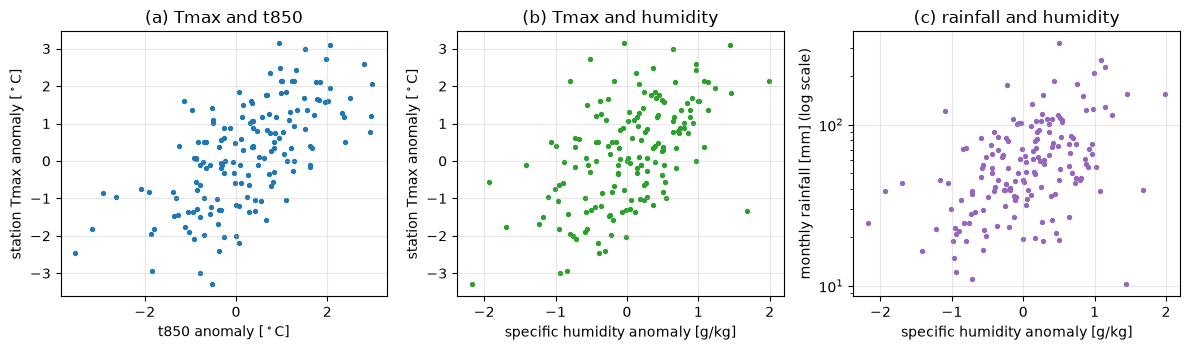

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
ax[0].scatter(cal.t850_C, cal.tmax_C, s=8); ax[0].set_xlabel("t850 anomaly [$^\\circ$C]"); ax[0].set_ylabel("station Tmax anomaly [$^\\circ$C]")
ax[1].scatter(cal.q_gkg, cal.tmax_C, s=8, color="tab:green"); ax[1].set_xlabel("specific humidity anomaly [g/kg]"); ax[1].set_ylabel("station Tmax anomaly [$^\\circ$C]")
ax[2].scatter(cal.q_gkg, cal.rain_mm, s=8, color="tab:purple"); ax[2].set_yscale("log")
ax[2].set_xlabel("specific humidity anomaly [g/kg]"); ax[2].set_ylabel("monthly rainfall [mm] (log scale)")
for a, t in zip(ax, ["(a) Tmax and t850", "(b) Tmax and humidity", "(c) rainfall and humidity"]): a.set_title(t)
fig.tight_layout()
print(cal[["slp_hPa", "q_gkg", "t850_C", "t2m_C", "tmax_C"]].corr().round(2))

Tmax is clearly related to the large-scale temperature and humidity, and rainfall rises with humidity but is scattered. The correlation table shows that `t850_C` and `t2m_C` are correlated at 0.98, which will matter in Section 5.

# 3) Simple linear regression: derivation

One predictor $x$ (say humidity) and one predictand $y$ (Tmax). The model for the pairs $(x_i, y_i)$, $i=1,\dots,n$ is

$$y_i = \beta_0 + \beta_1 x_i + \varepsilon_i, \qquad \varepsilon_i \sim N(0,\sigma^2)\ \text{independent}.$$

$\beta_0$ has the units of $y$, $\beta_1$ has units of $y$ per unit of $x$, and $\sigma$ has the units of $y$ (the noise that the predictor cannot explain). **Least squares** picks the line that makes the sum of squared errors smallest:

$$\mathrm{SSE}(b_0,b_1)=\sum_{i=1}^{n}\left(y_i-b_0-b_1x_i\right)^2 .$$

SSE is a smooth bowl-shaped function of $(b_0,b_1)$, so its minimum is where both partial derivatives vanish:

$$\frac{\partial \mathrm{SSE}}{\partial b_0}=-2\sum_i\left(y_i-b_0-b_1x_i\right)=0, \qquad
\frac{\partial \mathrm{SSE}}{\partial b_1}=-2\sum_i x_i\left(y_i-b_0-b_1x_i\right)=0 .$$

With the residual $e_i=y_i-b_0-b_1x_i$ these are the **normal equations** $\sum e_i=0$ and $\sum x_ie_i=0$: the residuals add up to zero and are uncorrelated with the predictor. The first gives, after dividing by $n$,

$$\bar y = b_0 + b_1\bar x \quad\Rightarrow\quad b_0=\bar y - b_1\bar x ,$$

so the line passes through the point of means. Substituting $b_0$ in the second equation, $\sum x_i y_i - b_0\sum x_i - b_1\sum x_i^2=0$, gives $\sum x_iy_i - n\bar x\bar y = b_1\left(\sum x_i^2 - n\bar x^2\right)$, and therefore

$$\boxed{\hat\beta_1=\frac{S_{xy}}{S_{xx}}=\frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2}=\frac{\mathrm{cov}(x,y)}{\mathrm{var}(x)}=r\,\frac{s_y}{s_x},\qquad \hat\beta_0=\bar y-\hat\beta_1\bar x}$$

where $r$ is the correlation coefficient and $s_x, s_y$ the sample standard deviations. Check the units: $[y]/[x]$, as they must be. Check the limits: if $x$ and $y$ are uncorrelated, $\hat\beta_1=0$ and the best prediction is just $\bar y$.

The code below applies the formula to 15 annual values by hand, and compares it with NumPy and SciPy. The same numbers sit in the sheet `SimpleReg` (cells `M8` to `M11`).

In [4]:
x = small.q_anom_gkg.to_numpy();  y = small.tmax_anom_C.to_numpy();  n = len(x)

xbar, ybar = x.mean(), y.mean()
Sxy = np.sum((x - xbar) * (y - ybar))
Sxx = np.sum((x - xbar) ** 2)
b1 = Sxy / Sxx
b0 = ybar - b1 * xbar
print(f"xbar = {xbar:.4f}  ybar = {ybar:.4f}  Sxy = {Sxy:.4f}  Sxx = {Sxx:.4f}")
print(f"by hand        : slope b1 = {b1:.4f}  intercept b0 = {b0:.4f}")

print("np.polyfit     :", np.round(np.polyfit(x, y, 1), 4), "(slope, intercept)")
lr = stats.linregress(x, y)
print(f"linregress     : slope = {lr.slope:.4f}  intercept = {lr.intercept:.4f}")

e = y - (b0 + b1 * x)
print(f"normal equations: sum(e) = {e.sum():.1e},  sum(x*e) = {np.sum(x*e):.1e}   (both zero up to round-off)")

xbar = -0.0813  ybar = -0.4380  Sxy = 2.7683  Sxx = 1.9750
by hand        : slope b1 = 1.4017  intercept b0 = -0.3240
np.polyfit     : [ 1.4017 -0.324 ] (slope, intercept)
linregress     : slope = 1.4017  intercept = -0.3240
normal equations: sum(e) = 1.1e-15,  sum(x*e) = -1.1e-15   (both zero up to round-off)


### What $R^2$ means, and how sure we are of the slope

Write $y_i - \bar y = (\hat y_i-\bar y) + e_i$. Squaring and summing, the cross term $2\sum(\hat y_i-\bar y)e_i$ vanishes because $\sum e_i=0$ and $\sum x_ie_i=0$ (the fitted values are a linear function of $x$). So

$$\underbrace{\sum(y_i-\bar y)^2}_{\mathrm{SST}}=\underbrace{\sum(\hat y_i-\bar y)^2}_{\mathrm{SSR}}+\underbrace{\sum e_i^2}_{\mathrm{SSE}},\qquad
R^2=\frac{\mathrm{SSR}}{\mathrm{SST}}=1-\frac{\mathrm{SSE}}{\mathrm{SST}}=r^2 .$$

$R^2$ is the **fraction of the variance of $y$ explained by the predictor** (0 to 1, dimensionless). It will be the key number in Section 8.

**Standard errors.** The slope can be written $\hat\beta_1=\sum (x_i-\bar x)y_i/S_{xx}$, a weighted sum of the independent $y_i$, so $\mathrm{Var}(\hat\beta_1)=\sigma^2\sum(x_i-\bar x)^2/S_{xx}^2=\sigma^2/S_{xx}$. We do not know $\sigma^2$ and estimate it from the residuals,

$$s_e^2=\frac{\mathrm{SSE}}{n-2},\qquad \mathrm{SE}(\hat\beta_1)=\frac{s_e}{\sqrt{S_{xx}}},$$

dividing by $n-2$ rather than $n$ because two parameters were estimated from the data (two degrees of freedom are used up). The noise is more precisely measured when $x$ is spread widely (large $S_{xx}$): a predictor with a large range pins down the slope.

**$t$-test of the slope.** To test $H_0:\beta_1=0$ (the predictor is useless) use

$$t=\frac{\hat\beta_1}{\mathrm{SE}(\hat\beta_1)}\sim t_{n-2}\ \text{under } H_0 ,$$

and reject at level $\alpha$ if $|t|>t_{1-\alpha/2,\,n-2}$. For a small sample the cut-off must be a *$t$ quantile*, which is larger than the normal value 1.96. A $(1-\alpha)$ **confidence interval** for the slope is $\hat\beta_1\pm t_{1-\alpha/2,n-2}\,\mathrm{SE}(\hat\beta_1)$.

**$F$-test.** The same question in variance terms: $F=\dfrac{\mathrm{SSR}/1}{\mathrm{SSE}/(n-2)}\sim F_{1,n-2}$. With one predictor $F=t^2$, and the two tests give the same $p$-value.

**Two kinds of interval at a new $x_0$.** The prediction is $\hat y_0=\hat\beta_0+\hat\beta_1x_0$. Its *line* is uncertain by $\mathrm{Var}(\hat y_0)=\sigma^2\left[\frac1n+\frac{(x_0-\bar x)^2}{S_{xx}}\right]$, which grows when $x_0$ is far from the calibration mean (extrapolation!). A single new *observation* also contains its own noise $\varepsilon_0$, adding $\sigma^2$:

$$\text{confidence interval: } \hat y_0 \pm t\,s_e\sqrt{\tfrac1n+\tfrac{(x_0-\bar x)^2}{S_{xx}}},\qquad
\text{prediction interval: } \hat y_0 \pm t\,s_e\sqrt{1+\tfrac1n+\tfrac{(x_0-\bar x)^2}{S_{xx}}} .$$

The confidence interval says where the *average* Tmax for this humidity lies; the prediction interval says where an individual *year* will fall, and is much wider. It is the prediction interval that matters for extremes.

R2 = 0.4646   (r^2 = 0.4646, SSR + SSE = SST: 8.3520 = 8.3520)
s_e = 0.5865   SE(b1) = 0.4173
t = 3.359   critical t(0.975, 13) = 2.160  (not 1.96!)   p = 0.0051
F = 11.281 = t^2 = 11.281   p(F) = 0.0051
95% CI of the slope: [0.500, 2.303]
sheet SimpleReg: R2 = M17, t = M25, t critical = M26, p = M27, F = M28

x0 = 0.5: prediction 0.377   CI [-0.241, 0.995]   PI [-1.033, 1.787]


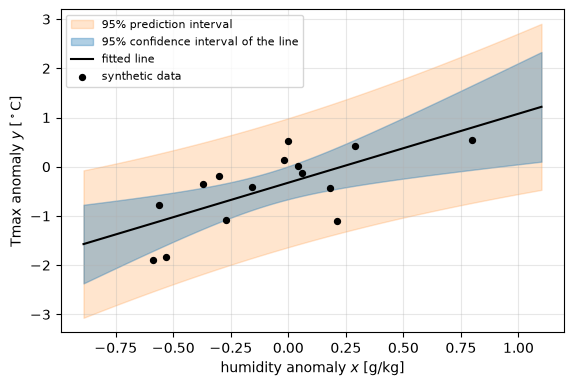

In [5]:
df_ = n - 2
SSE = np.sum(e**2);  SST = np.sum((y - ybar)**2);  SSR = SST - SSE
R2 = SSR / SST
s2 = SSE / df_
se_b1 = np.sqrt(s2 / Sxx)
t = b1 / se_b1
alpha = 0.05
tcrit = stats.t.ppf(1 - alpha / 2, df_)
p = 2 * stats.t.sf(abs(t), df_)
F = SSR / (SSE / df_)
pF = stats.f.sf(F, 1, df_)

print(f"R2 = {R2:.4f}   (r^2 = {np.corrcoef(x, y)[0,1]**2:.4f}, SSR + SSE = SST: {SSR + SSE:.4f} = {SST:.4f})")
print(f"s_e = {np.sqrt(s2):.4f}   SE(b1) = {se_b1:.4f}")
print(f"t = {t:.3f}   critical t(0.975, {df_}) = {tcrit:.3f}  (not 1.96!)   p = {p:.4f}")
print(f"F = {F:.3f} = t^2 = {t**2:.3f}   p(F) = {pF:.4f}")
print(f"95% CI of the slope: [{b1 - tcrit*se_b1:.3f}, {b1 + tcrit*se_b1:.3f}]")
print("sheet SimpleReg: R2 = M17, t = M25, t critical = M26, p = M27, F = M28")

x0 = 0.5
y0 = b0 + b1 * x0
sem = np.sqrt(s2 * (1/n + (x0 - xbar)**2 / Sxx))
sep = np.sqrt(s2 * (1 + 1/n + (x0 - xbar)**2 / Sxx))
print(f"\nx0 = {x0}: prediction {y0:.3f}   CI [{y0 - tcrit*sem:.3f}, {y0 + tcrit*sem:.3f}]   PI [{y0 - tcrit*sep:.3f}, {y0 + tcrit*sep:.3f}]")

xs = np.linspace(x.min() - 0.3, x.max() + 0.3, 100)
ys = b0 + b1 * xs
cb = tcrit * np.sqrt(s2 * (1/n + (xs - xbar)**2 / Sxx))
pb = tcrit * np.sqrt(s2 * (1 + 1/n + (xs - xbar)**2 / Sxx))
plt.figure(figsize=(6.5, 4.2))
plt.fill_between(xs, ys - pb, ys + pb, color="tab:orange", alpha=0.2, label="95% prediction interval")
plt.fill_between(xs, ys - cb, ys + cb, color="tab:blue", alpha=0.35, label="95% confidence interval of the line")
plt.plot(xs, ys, "k", lw=1.5, label="fitted line")
plt.scatter(x, y, color="k", s=18, zorder=3, label="synthetic data")
plt.xlabel("humidity anomaly $x$ [g/kg]"); plt.ylabel("Tmax anomaly $y$ [$^\\circ$C]"); plt.legend(fontsize=8);

With $n=15$ the cut-off is $t_{0.975,13}\approx 2.16$ rather than 1.96, and the slope is clearly nonzero ($p\approx 0.005$). The orange band is much wider than the blue one, and both widen away from $\bar x$: downscaling a GCM value far outside the calibration range is the least certain case.

# 4) Multiple linear regression in matrix form

Real downscaling uses several predictors. With $p$ predictors the model for case $i$ is $y_i=\beta_0+\beta_1x_{i1}+\dots+\beta_px_{ip}+\varepsilon_i$. Stack the $n$ cases into

$$\mathbf y=\mathbf X\boldsymbol\beta+\boldsymbol\varepsilon,\qquad
\mathbf X=\begin{pmatrix}1&x_{11}&\cdots&x_{1p}\\ \vdots&\vdots&&\vdots\\ 1&x_{n1}&\cdots&x_{np}\end{pmatrix}\ (n\times(p+1)),\quad
\boldsymbol\beta=\begin{pmatrix}\beta_0\\ \vdots\\ \beta_p\end{pmatrix},$$

where the first column of ones carries the intercept. The sum of squared errors is $\mathrm{SSE}(\mathbf b)=(\mathbf y-\mathbf X\mathbf b)^\top(\mathbf y-\mathbf X\mathbf b)$. Expanding,

$$\mathrm{SSE}=\mathbf y^\top\mathbf y-2\,\mathbf b^\top\mathbf X^\top\mathbf y+\mathbf b^\top\mathbf X^\top\mathbf X\,\mathbf b .$$

For a vector $\mathbf a$ and a symmetric matrix $\mathbf A$ the derivative rules are $\partial(\mathbf b^\top\mathbf a)/\partial\mathbf b=\mathbf a$ and $\partial(\mathbf b^\top\mathbf A\mathbf b)/\partial\mathbf b=2\mathbf A\mathbf b$, so setting the gradient to zero,

$$-2\mathbf X^\top\mathbf y+2\mathbf X^\top\mathbf X\,\mathbf b=\mathbf 0
\ \Rightarrow\ \mathbf X^\top\mathbf X\,\mathbf b=\mathbf X^\top\mathbf y\ \ (\text{normal equations})
\ \Rightarrow\ \boxed{\hat{\boldsymbol\beta}=(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf y}$$

provided $\mathbf X^\top\mathbf X$ can be inverted, i.e. no predictor is an exact linear combination of the others. **Sanity check.** For one predictor, $\mathbf X^\top\mathbf X=\begin{pmatrix}n&\sum x\\ \sum x&\sum x^2\end{pmatrix}$ and $\mathbf X^\top\mathbf y=\begin{pmatrix}\sum y\\ \sum xy\end{pmatrix}$; solving this $2\times2$ system gives the slope and intercept of Section 3 (the code below checks it numerically).

Because $\hat{\boldsymbol\beta}=\boldsymbol\beta+(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\boldsymbol\varepsilon$, its covariance is $\mathrm{Cov}(\hat{\boldsymbol\beta})=\sigma^2(\mathbf X^\top\mathbf X)^{-1}$, so

$$\mathrm{SE}(\hat\beta_j)=s_e\sqrt{\left[(\mathbf X^\top\mathbf X)^{-1}\right]_{jj}},\qquad s_e^2=\frac{\mathrm{SSE}}{n-p-1}.$$

The divisor is $n-p-1$: $p+1$ parameters were estimated. Each coefficient has its own $t$-test with $n-p-1$ degrees of freedom, and the overall $F$-test asks whether *any* predictor helps: $F=\dfrac{\mathrm{SSR}/p}{\mathrm{SSE}/(n-p-1)}\sim F_{p,\,n-p-1}$.

**The hat matrix in one paragraph.** The fitted values are $\hat{\mathbf y}=\mathbf X\hat{\boldsymbol\beta}=\mathbf H\mathbf y$ with $\mathbf H=\mathbf X(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top$, the matrix that "puts the hat on $\mathbf y$". It is the projection of $\mathbf y$ onto the space spanned by the columns of $\mathbf X$, so it is symmetric, $\mathbf H\mathbf H=\mathbf H$, and its trace is $p+1$. The diagonal element $h_{ii}$ is the *leverage* of case $i$ (how strongly $y_i$ pulls its own fitted value; the average is $(p+1)/n$), and the residuals $\mathbf e=(\mathbf I-\mathbf H)\mathbf y$ are orthogonal to every column of $\mathbf X$.

**Adjusted $R^2$.** Adding a predictor can never lower $R^2$, even a random one. To penalise useless predictors,

$$R^2_{\mathrm{adj}}=1-(1-R^2)\frac{n-1}{n-p-1},$$

which rises only if the new predictor reduces the residual variance more than chance would. We now fit Tmax on sea-level pressure, humidity and 850 hPa temperature, using the 160 calibration months. The sheets `MultiReg` (matrix steps with `MMULT` and `MINVERSE`, then `LINEST`) show the same.

In [6]:
pred3 = ["slp_hPa", "q_gkg", "t850_C"]
X = np.column_stack([np.ones(len(cal)), cal[pred3].to_numpy()])
yv = cal.tmax_C.to_numpy()
nobs, k = X.shape; p_ = k - 1

XtX = X.T @ X
Xty = X.T @ yv
beta = np.linalg.inv(XtX) @ Xty                          # the boxed formula
beta_lstsq = np.linalg.lstsq(X, yv, rcond=None)[0]        # numerically safer solver
print("X'X (4x4):\n", np.round(XtX, 2))
print("beta, inverse formula:", np.round(beta, 4))
print("beta, np.linalg.lstsq:", np.round(beta_lstsq, 4), "  max difference:", np.abs(beta - beta_lstsq).max())

# one predictor: does the matrix formula reproduce Section 3?
X1 = np.column_stack([np.ones(n), x]); b_1p = np.linalg.solve(X1.T @ X1, X1.T @ y)
print("\none predictor, matrix form (b0, b1):", np.round(b_1p, 4), "  Section 3:", np.round([b0, b1], 4))

fit = X @ beta; res = yv - fit
SSE_m = np.sum(res**2); SST_m = np.sum((yv - yv.mean())**2)
dfm = nobs - p_ - 1
s2_m = SSE_m / dfm
se_m = np.sqrt(s2_m * np.diag(np.linalg.inv(XtX)))
t_m = beta / se_m
p_m = 2 * stats.t.sf(np.abs(t_m), dfm)
R2_m = 1 - SSE_m / SST_m
R2a_m = 1 - (1 - R2_m) * (nobs - 1) / dfm
F_m = ((SST_m - SSE_m) / p_) / (SSE_m / dfm)

print(pd.DataFrame({"coef": beta, "SE": se_m, "t": t_m, "p-value": p_m}, index=["intercept"] + pred3).round(4).to_string())
print(f"\nR2 = {R2_m:.4f}   adjusted R2 = {R2a_m:.4f}   s_e = {np.sqrt(s2_m):.3f} C   F({p_},{dfm}) = {F_m:.2f}   p(F) = {stats.f.sf(F_m, p_, dfm):.1e}")
print("sheet MultiReg: beta = K24:K27, R2 = N37, adjusted R2 = N38, F = N41")

H = X @ np.linalg.inv(XtX) @ X.T                          # 160 x 160 hat matrix
print(f"\nhat matrix: symmetric {np.allclose(H, H.T)}, idempotent {np.allclose(H @ H, H)}, trace = {np.trace(H):.3f} (p+1 = {k}),"
      f" max leverage = {np.diag(H).max():.3f}, mean leverage = {np.diag(H).mean():.3f}")
print("residuals orthogonal to every column of X:", np.round(X.T @ res, 8))

X'X (4x4):
 [[160.     5.06   5.61  40.07]
 [  5.06 510.97 -51.89  65.63]
 [  5.61 -51.89  76.28  62.33]
 [ 40.07  65.63  62.33 239.32]]
beta, inverse formula: [ 0.0163 -0.1397  0.4526  0.6418]
beta, np.linalg.lstsq: [ 0.0163 -0.1397  0.4526  0.6418]   max difference: 7.771561172376096e-16

one predictor, matrix form (b0, b1): [-0.324   1.4017]   Section 3: [-0.324   1.4017]
             coef      SE       t  p-value
intercept  0.0163  0.0782  0.2082   0.8353
slp_hPa   -0.1397  0.0475 -2.9389   0.0038
q_gkg      0.4526  0.1363  3.3196   0.0011
t850_C     0.6418  0.0771  8.3217   0.0000

R2 = 0.5083   adjusted R2 = 0.4989   s_e = 0.966 C   F(3,156) = 53.76   p(F) = 6.4e-24
sheet MultiReg: beta = K24:K27, R2 = N37, adjusted R2 = N38, F = N41

hat matrix: symmetric True, idempotent True, trace = 4.000 (p+1 = 4), max leverage = 0.078, mean leverage = 0.025
residuals orthogonal to every column of X: [-0. -0.  0.  0.]


The intercept is close to zero (anomalies), and the other coefficients are significant: warm 850 hPa air and moist air raise Tmax, and high pressure (clear, dry sky) lowers Tmax relative to the others. About half of the variance is explained, and the adjusted $R^2$ is only slightly below $R^2$ because the three predictors are all useful.

# 5) Multicollinearity and the variance inflation factor

If two predictors carry almost the same information, $\mathbf X^\top\mathbf X$ is close to singular and $(\mathbf X^\top\mathbf X)^{-1}$ has huge entries. By the formula above, the standard errors of the coefficients explode. In words: the regression cannot tell *which* of the two variables is responsible and may give one a large positive and the other a large negative coefficient.

Let $R_j^2$ be the $R^2$ obtained by regressing predictor $x_j$ on all the *other* predictors. Then

$$\mathrm{Var}(\hat\beta_j)=\frac{\sigma^2}{S_{jj}\,(1-R_j^2)},\qquad \mathrm{VIF}_j=\frac{1}{1-R_j^2},$$

with $S_{jj}=\sum(x_{ij}-\bar x_j)^2$. Compared with a predictor that is uncorrelated with the others, the variance is inflated by $\mathrm{VIF}_j$ and the standard error by $\sqrt{\mathrm{VIF}_j}$. A computational shortcut: the VIFs are the **diagonal of the inverse of the predictors' correlation matrix**. A VIF above about 5&ndash;10 signals a problem.

The demonstration adds the 2 m temperature (`t2m_C`, 0.98 correlated with `t850_C`) to the predictors. The sheet `Collinearity` computes the VIF with `MINVERSE` of the correlation matrix. To see the *instability* we resample the 40 calibration years with replacement 300 times (the bootstrap), refit each time, and look at the spread of the coefficients.

correlation matrix:
 [[1.    0.461 0.455]
 [0.461 1.    0.977]
 [0.455 0.977 1.   ]]
VIF (q, t850, t2m): [ 1.27 22.   21.84]    (sheet Collinearity B17:B19)
R_j^2 of t850 on (q, t2m) = 0.9545  ->  1/(1-R_j^2) = 22.00

model A (q, t850, t2m): b_t850 = 0.563 (SE 0.307)   b_t2m = -0.003 (SE 0.314)   b_t850 + b_t2m = 0.560
model B (q, t850)     : b_t850 = 0.560 (SE 0.074)
SE(b_t850) ratio A/B = 4.17   sqrt(VIF of t850) = 4.69
validation RMSE: model A 1.021 C, model B 1.022 C


bootstrap SD: b_t850 in A = 0.323, in B = 0.067, sum in A = 0.071


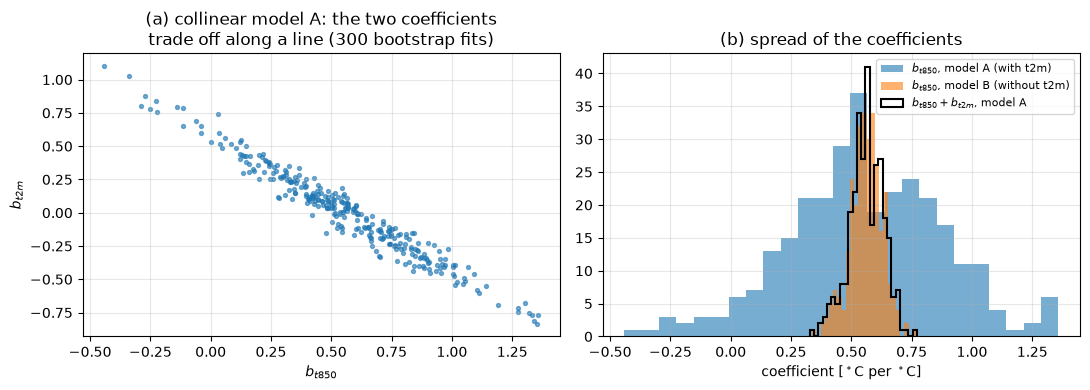

In [7]:
names3 = ["q_gkg", "t850_C", "t2m_C"]
Rm = np.corrcoef(cal[names3].to_numpy().T)
vif = np.diag(np.linalg.inv(Rm))
print("correlation matrix:\n", np.round(Rm, 3))
print("VIF (q, t850, t2m):", np.round(vif, 2), "   (sheet Collinearity B17:B19)")

# check the shortcut for t850: regress it on the other two predictors
Zo = np.column_stack([np.ones(len(cal)), cal[["q_gkg", "t2m_C"]]]); tt = cal.t850_C.to_numpy()
r2_j = 1 - np.sum((tt - Zo @ np.linalg.lstsq(Zo, tt, rcond=None)[0])**2) / np.sum((tt - tt.mean())**2)
print(f"R_j^2 of t850 on (q, t2m) = {r2_j:.4f}  ->  1/(1-R_j^2) = {1/(1-r2_j):.2f}")

def ols(df, cols):
    Xm = np.column_stack([np.ones(len(df)), df[cols].to_numpy()])
    b = np.linalg.lstsq(Xm, df.tmax_C.to_numpy(), rcond=None)[0]
    r = df.tmax_C.to_numpy() - Xm @ b
    se = np.sqrt(np.sum(r**2) / (len(df) - Xm.shape[1]) * np.diag(np.linalg.inv(Xm.T @ Xm)))
    return b, se

A_cols, B_cols = ["q_gkg", "t850_C", "t2m_C"], ["q_gkg", "t850_C"]
bA, seA = ols(cal, A_cols); bB, seB = ols(cal, B_cols)
print(f"\nmodel A (q, t850, t2m): b_t850 = {bA[2]:.3f} (SE {seA[2]:.3f})   b_t2m = {bA[3]:.3f} (SE {seA[3]:.3f})   b_t850 + b_t2m = {bA[2] + bA[3]:.3f}")
print(f"model B (q, t850)     : b_t850 = {bB[2]:.3f} (SE {seB[2]:.3f})")
print(f"SE(b_t850) ratio A/B = {seA[2]/seB[2]:.2f}   sqrt(VIF of t850) = {np.sqrt(vif[1]):.2f}")

# prediction quality in validation does not suffer
def rmse_val(cols):
    Xc = np.column_stack([np.ones(len(cal)), cal[cols]]); b = np.linalg.lstsq(Xc, cal.tmax_C, rcond=None)[0]
    Xv = np.column_stack([np.ones(len(val)), val[cols]]); return np.sqrt(np.mean((Xv @ b - val.tmax_C)**2))
print(f"validation RMSE: model A {rmse_val(A_cols):.3f} C, model B {rmse_val(B_cols):.3f} C")

rng = np.random.default_rng(0)
years = np.unique(cal.year)
bootA = np.empty((300, 4)); bootB = np.empty((300, 3))
for i in range(300):
    ys_ = rng.choice(years, size=len(years), replace=True)
    d = pd.concat([cal[cal.year == yy] for yy in ys_])
    bootA[i] = ols(d, A_cols)[0]; bootB[i] = ols(d, B_cols)[0]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(bootA[:, 2], bootA[:, 3], s=8, alpha=0.6)
ax[0].set_xlabel("$b_{t850}$"); ax[0].set_ylabel("$b_{t2m}$"); ax[0].set_title("(a) collinear model A: the two coefficients\ntrade off along a line (300 bootstrap fits)")
ax[1].hist(bootA[:, 2], bins=25, alpha=0.6, label="$b_{t850}$, model A (with t2m)")
ax[1].hist(bootB[:, 2], bins=25, alpha=0.6, label="$b_{t850}$, model B (without t2m)")
ax[1].hist(bootA[:, 2] + bootA[:, 3], bins=25, histtype="step", color="k", lw=1.5, label="$b_{t850}+b_{t2m}$, model A")
ax[1].set_xlabel("coefficient [$^\\circ$C per $^\\circ$C]"); ax[1].legend(fontsize=8); ax[1].set_title("(b) spread of the coefficients")
fig.tight_layout()
print(f"bootstrap SD: b_t850 in A = {bootA[:,2].std():.3f}, in B = {bootB[:,2].std():.3f}, sum in A = {(bootA[:,2]+bootA[:,3]).std():.3f}")

The VIFs of `t850_C` and `t2m_C` are about 22 (R$_j^2\approx 0.95$), and the standard error of the `t850` coefficient is about $\sqrt{22}\approx 4.7$ times larger when `t2m` is included. The scatter plot shows the coefficients sliding along a line: one goes up when the other goes down, but their **sum** is stable. The *prediction* is therefore almost as good as before (the validation RMSE barely changes), while the *interpretation* of a single coefficient is lost. In downscaling the remedy is to drop or combine near-duplicates, or to reduce the predictors to a few uncorrelated components (Lecture 20).

# 6) Residual diagnostics

The tests and intervals of Section 3 assume that the errors $\varepsilon_i$ are (i) **normal**, (ii) **independent** of each other and (iii) of **constant variance**. We never see $\varepsilon_i$ but we see the residuals $e_i$, and four plots check the assumptions.

- *Residual against fitted value:* a curve means the link is not linear; a funnel means the variance changes with the level (heteroscedasticity).
- *Normal quantile plot:* points on the line mean normal errors; heavy tails curve away.
- *Autocorrelation of the residuals in time:* bars outside the band $\pm1.96/\sqrt n$ mean the errors are not independent, so the effective sample size is smaller than $n$ and the standard errors are too small. This is common in daily data.
- *Residual against time:* a drift means something that changes in time is missing (stationarity, Section 7).

Shapiro-Wilk p = 0.886 (normality not rejected if p > 0.05)
lag-1 autocorrelation = 0.006   (band +/- 0.155);  Durbin-Watson = 1.98 (about 2 = none)
correlation of |residual| with fitted value = -0.137 (about 0 = constant variance)


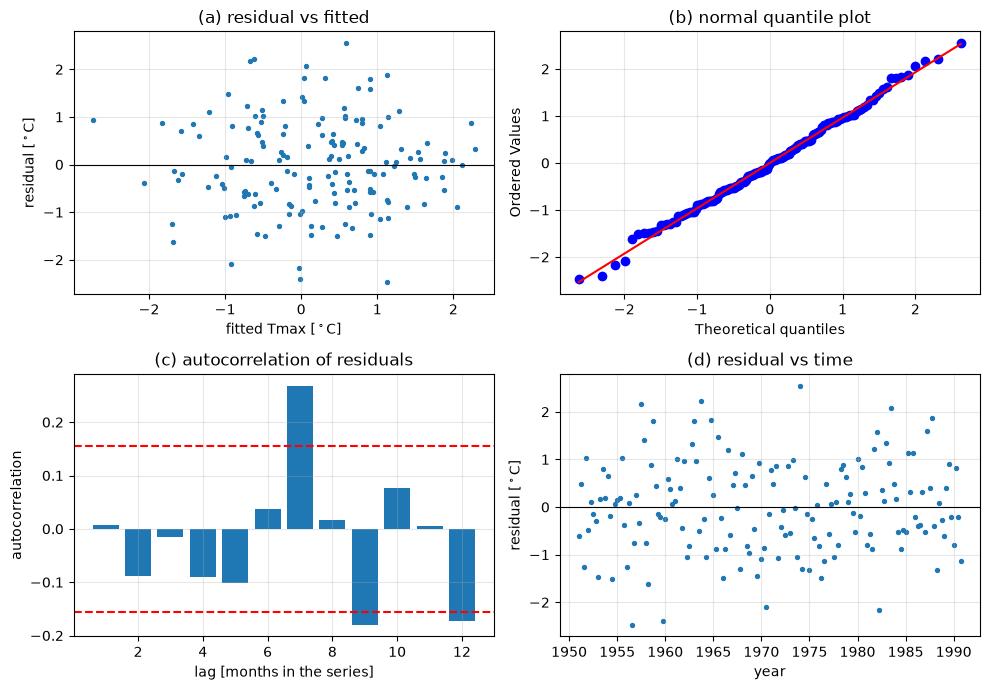

In [8]:
fit_cal = X @ beta
res = yv - fit_cal

def acf(r, nlag=12):
    r = r - r.mean()
    return np.array([np.sum(r[l:] * r[:len(r) - l]) / np.sum(r * r) for l in range(1, nlag + 1)])

fig, ax = plt.subplots(2, 2, figsize=(10, 7))
ax[0, 0].scatter(fit_cal, res, s=8); ax[0, 0].axhline(0, color="k", lw=0.8)
ax[0, 0].set_xlabel("fitted Tmax [$^\\circ$C]"); ax[0, 0].set_ylabel("residual [$^\\circ$C]"); ax[0, 0].set_title("(a) residual vs fitted")
stats.probplot(res, dist="norm", plot=ax[0, 1]); ax[0, 1].set_title("(b) normal quantile plot")
a = acf(res); band = 1.96 / np.sqrt(len(res))
ax[1, 0].bar(range(1, 13), a); ax[1, 0].axhline(band, color="r", ls="--"); ax[1, 0].axhline(-band, color="r", ls="--")
ax[1, 0].set_xlabel("lag [months in the series]"); ax[1, 0].set_ylabel("autocorrelation"); ax[1, 0].set_title("(c) autocorrelation of residuals")
ax[1, 1].scatter(cal.year + (cal.month - 6) / 4, res, s=8); ax[1, 1].axhline(0, color="k", lw=0.8)
ax[1, 1].set_xlabel("year"); ax[1, 1].set_ylabel("residual [$^\\circ$C]"); ax[1, 1].set_title("(d) residual vs time")
fig.tight_layout()

print(f"Shapiro-Wilk p = {stats.shapiro(res).pvalue:.3f} (normality not rejected if p > 0.05)")
print(f"lag-1 autocorrelation = {a[0]:.3f}   (band +/- {band:.3f});  Durbin-Watson = {np.sum(np.diff(res)**2) / np.sum(res**2):.2f} (about 2 = none)")
print(f"correlation of |residual| with fitted value = {np.corrcoef(np.abs(res), fit_cal)[0,1]:.3f} (about 0 = constant variance)")

For this synthetic series the checks look fine, as they should, because the noise was generated normal, independent and of constant variance. (One autocorrelation bar, at lag 7, pokes just outside the band; with 12 lags one bar in twenty is expected to do so by chance, and there is no physical reason for a 7-month lag in a series of four months per year.) Real data rarely behave so well: monthly rainfall residuals are skewed (hence the logarithm in Section 8), and daily residuals are autocorrelated and have a variance that grows with the rainfall amount.

# 7) Standardising predictors, checking stationarity, and applying to the GCM

**Standardisation.** Predictors have different units and sizes (pressure in hPa, humidity in g/kg, perhaps pressure in Pa in the GCM file). Convert each to a unitless $z$-score, $z=(x-\bar x_{\mathrm{base}})/s_{\mathrm{base}}$. The fitted slope on $z_j$ is $\beta_js_j$ (in units of $y$ per standard deviation of $x_j$), so coefficients become comparable, and a unit mismatch between reanalysis and GCM cannot occur. Two rules matter in downscaling:

- the mean and standard deviation come from the **base (calibration) period only**, also when the future is standardised, otherwise the climate-change signal in the mean and variance is removed;
- the GCM predictors are standardised with the **GCM's own base-period** mean and standard deviation, which removes the GCM's mean bias and its error in the predictor variance. (Whether the future variance should be kept or rescaled is a modelling choice; here the base-period values are used.)

**Stationarity.** The fitted relationship is assumed to hold in a different climate. We cannot test the future, but we can test *other periods of the past*: calibrate on one period, validate on another, and then swap. If the skill drops or a bias appears, the relationship is not stable, and the downscaled future should not be trusted. The best test is a warm period against a cold one. We use bias, RMSE, $R^2$ and the ratio of standard deviations (sheet `CalVal`).

standardised coefficients (SD of Tmax per SD of predictor): {'slp_hPa': -0.184, 'q_gkg': 0.229, 't850_C': 0.565}
beta * SD(x) / SD(y) from the raw fit                    : [-0.184  0.229  0.565]   (sheet CalVal K18:K20)
t850 and humidity matter most; pressure least.

                                    bias   RMSE     R2  SD_ratio
calibration 1951-90               -0.000  0.954  0.508     0.713
validation 1991-2020              -0.041  0.942  0.686     0.687
swap: fit 1991-2020, test 1951-90 -0.011  0.974  0.506     0.848
sheet CalVal I5:J12 (bias, RMSE, correlation, R2, skill, SDs, SD ratio)


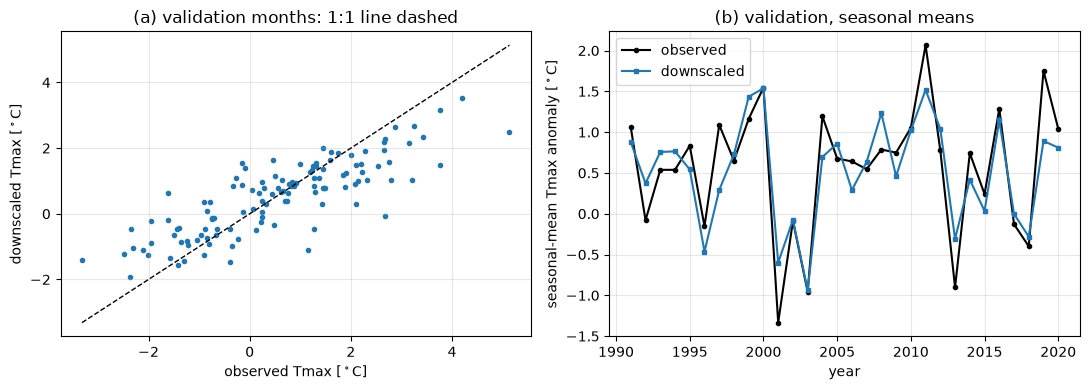

In [9]:
mu = cal[pred3].mean().to_numpy(); sd = cal[pred3].std(ddof=1).to_numpy()
ymu, ysd = cal.tmax_C.mean(), cal.tmax_C.std(ddof=1)

def zscore(df, mu_=mu, sd_=sd): return (df[pred3].to_numpy() - mu_) / sd_
Zc = np.column_stack([np.ones(len(cal)), zscore(cal)])
bz = np.linalg.lstsq(Zc, (cal.tmax_C.to_numpy() - ymu) / ysd, rcond=None)[0]

print("standardised coefficients (SD of Tmax per SD of predictor):", {k_: round(float(v_), 3) for k_, v_ in zip(pred3, bz[1:])})
print("beta * SD(x) / SD(y) from the raw fit                    :", np.round(beta[1:] * sd / ysd, 3), "  (sheet CalVal K18:K20)")
print("t850 and humidity matter most; pressure least.\n")

def to_obs_units(Z, b): return (Z @ b) * ysd + ymu           # standardised model, back-transformed to Tmax in C

def metrics(obs, prd):
    err = prd - obs
    return dict(bias=err.mean(), RMSE=np.sqrt(np.mean(err**2)), R2=np.corrcoef(obs, prd)[0, 1]**2,
                SD_ratio=prd.std(ddof=1) / obs.std(ddof=1))

Zv = np.column_stack([np.ones(len(val)), zscore(val)])
tab = pd.DataFrame({"calibration 1951-90": metrics(cal.tmax_C.to_numpy(), to_obs_units(Zc, bz)),
                    "validation 1991-2020": metrics(val.tmax_C.to_numpy(), to_obs_units(Zv, bz))}).T

# swap test: calibrate on 1991-2020, validate on 1951-1990
mu2, sd2 = val[pred3].mean().to_numpy(), val[pred3].std(ddof=1).to_numpy(); ym2, ys2 = val.tmax_C.mean(), val.tmax_C.std(ddof=1)
bz2 = np.linalg.lstsq(np.column_stack([np.ones(len(val)), zscore(val, mu2, sd2)]), (val.tmax_C.to_numpy() - ym2) / ys2, rcond=None)[0]
swap = np.column_stack([np.ones(len(cal)), zscore(cal, mu2, sd2)]) @ bz2 * ys2 + ym2
tab.loc["swap: fit 1991-2020, test 1951-90"] = metrics(cal.tmax_C.to_numpy(), swap)
print(tab.round(3).to_string())
print("sheet CalVal I5:J12 (bias, RMSE, correlation, R2, skill, SDs, SD ratio)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
pv = to_obs_units(Zv, bz)
ax[0].scatter(val.tmax_C, pv, s=9); lim = [min(val.tmax_C.min(), pv.min()), max(val.tmax_C.max(), pv.max())]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set_xlabel("observed Tmax [$^\\circ$C]"); ax[0].set_ylabel("downscaled Tmax [$^\\circ$C]"); ax[0].set_title("(a) validation months: 1:1 line dashed")
ann = val.assign(pred=pv).groupby("year")[["tmax_C", "pred"]].mean()
ax[1].plot(ann.index, ann.tmax_C, "k-o", ms=3, label="observed"); ax[1].plot(ann.index, ann.pred, "-s", ms=3, label="downscaled")
ax[1].set_xlabel("year"); ax[1].set_ylabel("seasonal-mean Tmax anomaly [$^\\circ$C]"); ax[1].legend(); ax[1].set_title("(b) validation, seasonal means")
fig.tight_layout();

The bias in the independent validation period is near zero and the skill is at least as good as in calibration (the validation $R^2$ is even higher, because the warming trend of 850 hPa temperature adds predictable variance), and the swapped test is also acceptable, so the relationship is stable here (it is stable by construction; real data seldom pass so easily). Note the **SD ratio** below one in every row: the downscaled series is less variable than the observed one, even when all else is perfect. That is Section 8.

**Applying to the GCM.** The final step feeds the GCM predictors through the fitted function. Here the synthetic GCM has its own (slightly damped) variability and a strong warming and moistening in 2061&ndash;2100. A practical check is the fraction of future predictor values that fall **outside the calibration range**: there the fitted line is an extrapolation, and the prediction interval of Section 3 widens.

share of future months outside the calibration range: {'slp_hPa': 3.8, 'q_gkg': 7.5, 't850_C': 70.0} [%]
mean downscaled Tmax anomaly: GCM historical 0.19 C, GCM future 2.83 C, change 2.64 C
SD of the downscaled series : GCM historical 1.03 C, observed (calibration) 1.36 C


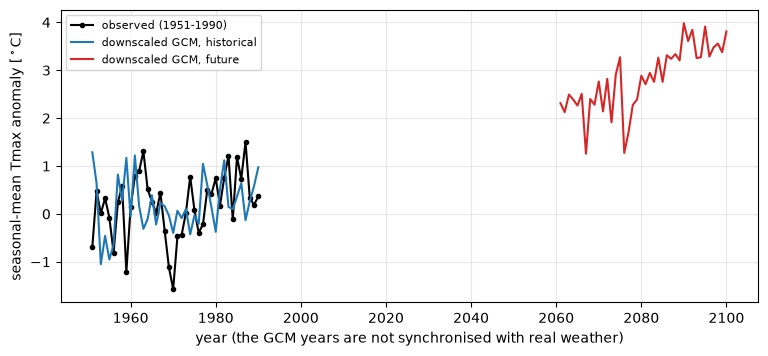

In [10]:
g_hist = gcm[gcm.scenario == "historical"]; g_fut = gcm[gcm.scenario == "future"]
mu_g, sd_g = g_hist[pred3].mean().to_numpy(), g_hist[pred3].std(ddof=1).to_numpy()     # GCM base-period statistics

def downscale(g): return to_obs_units(np.column_stack([np.ones(len(g)), zscore(g, mu_g, sd_g)]), bz)
yh, yf = downscale(g_hist), downscale(g_fut)

Zfut = zscore(g_fut, mu_g, sd_g); Zcal = zscore(cal)
outside = np.mean((Zfut < Zcal.min(axis=0)) | (Zfut > Zcal.max(axis=0)), axis=0)
print("share of future months outside the calibration range:", {k_: round(float(v_), 1) for k_, v_ in zip(pred3, 100 * outside)}, "[%]")
print(f"mean downscaled Tmax anomaly: GCM historical {yh.mean():.2f} C, GCM future {yf.mean():.2f} C, change {yf.mean() - yh.mean():.2f} C")
print(f"SD of the downscaled series : GCM historical {yh.std(ddof=1):.2f} C, observed (calibration) {ysd:.2f} C")

fig, ax = plt.subplots(figsize=(9, 3.8))
a_h = pd.Series(yh).groupby(g_hist.year.to_numpy()).mean(); a_f = pd.Series(yf).groupby(g_fut.year.to_numpy()).mean()
a_o = cal.groupby("year").tmax_C.mean()
ax.plot(a_o.index, a_o, "k-o", ms=3, label="observed (1951-1990)")
ax.plot(a_h.index, a_h, "-", color="tab:blue", label="downscaled GCM, historical")
ax.plot(a_f.index, a_f, "-", color="tab:red", label="downscaled GCM, future")
ax.set_xlabel("year (the GCM years are not synchronised with real weather)"); ax.set_ylabel("seasonal-mean Tmax anomaly [$^\\circ$C]"); ax.legend(fontsize=8);

The future mean rises by about 2.6 $^\circ$C in the downscaled series (the GCM's 850 hPa warming is larger, but the fitted slope is below one and the other predictors contribute too), carried entirely by the warming of the 850 hPa temperature and the moistening in the GCM. A large part of the future predictor values lies beyond anything seen in 1951&ndash;1990, so the result relies on the linear relation holding *outside* the calibration range, which is the stationarity assumption in its strongest form. The warming also appears in the output only because the predictor set includes a temperature variable; a predictor set of pressure alone could not have shown it.

# 8) The central weakness: the downscaled series is too smooth

Regression predicts the *conditional mean* of $y$ given the predictors, $\hat y=\mathbf x^\top\hat{\boldsymbol\beta}$. All the part of $y$ that the predictors cannot explain is dropped. Derive what is lost. Write $y_i=\hat y_i+e_i$. The residuals are uncorrelated with the fitted values (a consequence of the normal equations) and have zero mean, so

$$\mathrm{Var}(y)=\mathrm{Var}(\hat y)+\mathrm{Var}(e)
\quad\Rightarrow\quad
\mathrm{Var}(\hat y)=R^2\,\mathrm{Var}(y),\qquad \mathrm{Var}(e)=(1-R^2)\,\mathrm{Var}(y),$$

because $R^2=\mathrm{SSR}/\mathrm{SST}$ is the ratio of the first to the total term. The standard deviation of the downscaled series is therefore only $\sqrt{R^2}\,s_y$: with $R^2=0.5$ it keeps 71 % of the observed standard deviation, with $R^2=0.25$ only half. For a normally distributed variable this has a dramatic effect in the tail: an event at $+2\,s_y$ is $+2/\sqrt{R^2}$ times the spread of the fitted series, i.e. $+2.8$ standard deviations for $R^2=0.5$. Its frequency falls from 2.3 % to about 0.25 %, nearly ten times fewer. The *mean* is preserved, but **extremes, which are what floods, droughts and heat waves are made of, are the part that is lost.**

Two common fixes restore the variance.

1. **Variance inflation.** Stretch the deviations of the fitted series about its mean: $\hat y^{\mathrm{inf}}=\bar y+(\hat y-\bar y)/\sqrt{R^2}$. Its variance is exactly $\mathrm{Var}(y)$. It is deterministic and keeps the day-to-day timing of the fit. But it also inflates the *signal*: a climate-change shift in $\hat y$ is multiplied by $1/\sqrt{R^2}$, here about 1.4, which can overstate the warming.
2. **Residual noise (randomisation).** Add a random residual with the right variance: $\hat y^{\mathrm{noise}}=\hat y+s_e\,\xi$, $\xi\sim N(0,1)$. Then $\mathrm{Var}=R^2\mathrm{Var}(y)+(1-R^2)\mathrm{Var}(y)=\mathrm{Var}(y)$, and the climate-change shift is untouched. The price is that each run is one random realisation (several should be generated), and the series no longer follows the observed sequence day by day.

For rainfall we regress the **logarithm** of the monthly total, so that rainfall stays positive and the residuals are closer to normal, and add the noise on the log scale. The code uses the fixed `z_noise` column as $\xi$, as in the sheet `VarInfl`. The variance decomposition, the statistics of the validation months (1991&ndash;2020), and a Q&ndash;Q plot follow.

Tmax, calibration months
  Var(y) = 1.8611   Var(yhat) + Var(e) = 1.8611   R2 * Var(y) = 0.9460
  SD(yhat)/SD(y) = 0.713   sqrt(R2) = 0.713

ln(rain): coefficients [ 3.98  -0.112  0.382 -0.025]  R2 = 0.309  s_e = 0.552   (sheet VarInfl M4:M10)
  Var(ln rain) = 0.4321, Var(fitted) = 0.1336 (= R2 x Var), Var(resid) = 0.2985

Validation months 1991-2020, rainfall [mm]   (sheet VarInfl L20:P29)
                   mean    SD   P50    P90    P99    max  % months > obs P90  % months > obs P99
observed           70.5  49.0  52.7  139.3  218.5  224.6                10.0                 1.7
regression only    58.7  28.8  54.3   95.4  161.2  166.5                 3.3                 0.0
+ residual noise   66.3  48.2  50.6  135.4  220.8  322.4                 9.2                 1.7
variance inflated  73.4  72.9  54.8  150.9  388.1  410.7                10.8                 5.8
500 noise realisations, P90: median 129 mm, 5-95% range 110-154 mm   (observed 139 mm)
500 noise realisations, P99: media

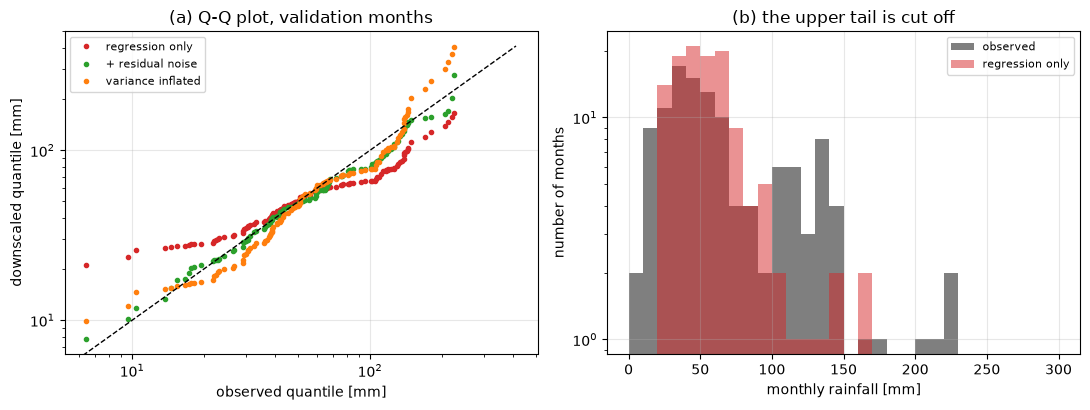

In [11]:
# --- Tmax: the variance decomposition, numerically
print("Tmax, calibration months")
print(f"  Var(y) = {yv.var(ddof=1):.4f}   Var(yhat) + Var(e) = {fit_cal.var(ddof=1) + res.var(ddof=1):.4f}   R2 * Var(y) = {R2_m * yv.var(ddof=1):.4f}")
print(f"  SD(yhat)/SD(y) = {fit_cal.std(ddof=1) / yv.std(ddof=1):.3f}   sqrt(R2) = {np.sqrt(R2_m):.3f}")

# --- rainfall: ln(rain) on the same three predictors, calibration months
lr_c = np.log(cal.rain_mm.to_numpy())
bl = np.linalg.lstsq(X, lr_c, rcond=None)[0]
fit_c = X @ bl;  resid_c = lr_c - fit_c
R2l = 1 - np.sum(resid_c**2) / np.sum((lr_c - lr_c.mean())**2)
sel = np.sqrt(np.sum(resid_c**2) / (len(lr_c) - 4))
print(f"\nln(rain): coefficients {np.round(bl, 3)}  R2 = {R2l:.3f}  s_e = {sel:.3f}   (sheet VarInfl M4:M10)")
print(f"  Var(ln rain) = {lr_c.var(ddof=1):.4f}, Var(fitted) = {fit_c.var(ddof=1):.4f} (= R2 x Var), Var(resid) = {resid_c.var(ddof=1):.4f}")

# --- apply to validation months, three versions
Xv = np.column_stack([np.ones(len(val)), val[pred3].to_numpy()])
fl = Xv @ bl
det = np.exp(fl)                                           # deterministic regression output
noi = np.exp(fl + sel * val.z_noise.to_numpy())            # + residual noise on the log scale
inf = np.exp(lr_c.mean() + (fl - lr_c.mean()) / np.sqrt(R2l))   # variance inflation on the log scale
obs = val.rain_mm.to_numpy()
p90, p99 = np.percentile(obs, 90), np.percentile(obs, 99)

rows = {}
for nm, a in {"observed": obs, "regression only": det, "+ residual noise": noi, "variance inflated": inf}.items():
    rows[nm] = dict(mean=a.mean(), SD=a.std(ddof=1), P50=np.percentile(a, 50), P90=np.percentile(a, 90), P99=np.percentile(a, 99),
                    max=a.max(), **{"% months > obs P90": 100 * np.mean(a > p90), "% months > obs P99": 100 * np.mean(a > p99)})
print("\nValidation months 1991-2020, rainfall [mm]   (sheet VarInfl L20:P29)")
print(pd.DataFrame(rows).T.round(1).to_string())

# one noise realisation is one possible future: repeat with 500 random draws (an ensemble)
rg = np.random.default_rng(1)
ens = np.exp(fl + sel * rg.standard_normal((500, len(val))))
for q_, ob in ((90, p90), (99, p99)):
    v_ = np.percentile(ens, q_, axis=1)
    print(f"500 noise realisations, P{q_}: median {np.median(v_):.0f} mm, 5-95% range {np.percentile(v_, 5):.0f}-{np.percentile(v_, 95):.0f} mm   (observed {ob:.0f} mm)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
srt = np.sort(obs); qs = (np.arange(1, len(obs) + 1) - 0.5) / len(obs)
for nm, a, c in (("regression only", det, "tab:red"), ("+ residual noise", noi, "tab:green"), ("variance inflated", inf, "tab:orange")):
    ax[0].plot(srt, np.quantile(a, qs), "o", ms=3, color=c, label=nm)
m_ = max(srt.max(), noi.max(), inf.max())
ax[0].plot([0, m_], [0, m_], "k--", lw=1); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("observed quantile [mm]"); ax[0].set_ylabel("downscaled quantile [mm]"); ax[0].legend(fontsize=8)
ax[0].set_title("(a) Q-Q plot, validation months")
ax[1].hist(obs, bins=np.linspace(0, 300, 31), alpha=0.5, label="observed", color="k")
ax[1].hist(det, bins=np.linspace(0, 300, 31), alpha=0.5, label="regression only", color="tab:red")
ax[1].set_yscale("log"); ax[1].set_xlabel("monthly rainfall [mm]"); ax[1].set_ylabel("number of months"); ax[1].legend(fontsize=8); ax[1].set_title("(b) the upper tail is cut off")
fig.tight_layout();

The deterministic regression (red) has the right middle of the distribution but a standard deviation well below the observed one, and almost no months above the observed 90th and 99th percentiles (the rows "% months > obs P90" and "P99", which should be 10 % and 1 %). The Q&ndash;Q plot shows the red points lying flat at the top end. Adding noise brings the exceedance fractions back close to 10 % and 1 % and restores the standard deviation, while the 500-member ensemble shows that a single realisation of a 99th percentile from 120 months is uncertain (190&ndash;364 mm). Variance inflation, which relies on the *calibration* $R^2$, overshoots in this validation sample because the validation predictors happen to vary more than the calibration ones (it is deterministic, so it also cannot give a spread). Remember two caveats: $\exp(\text{fitted log rainfall})$ estimates the *median*, not the mean, so the noise version has a mean larger by about $\exp(s_e^2/2)$; and noise makes each run one of many possible realisations, so one should generate an ensemble and report its spread.

Variance inflation and noise are fixes, not cures: they restore the *marginal* distribution but not the physical process. When rainfall occurrence, spells and day-to-day variability matter (for example for floods or droughts) the next tool is a weather generator, covered in Lecture 21.

# Summary

- **Perfect prognosis:** calibrate $y=f(\mathbf x)+\varepsilon$ on reanalysis and observations, apply $f$ to GCM predictors; it assumes a physical link, well-simulated predictors, a stationary relationship and predictors that carry the climate signal.
- **Least squares by calculus:** $\hat\beta_1=\mathrm{cov}(x,y)/\mathrm{var}(x)$, $\hat\beta_0=\bar y-\hat\beta_1\bar x$; in matrix form $\hat{\boldsymbol\beta}=(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf y$, with residuals orthogonal to the predictors and $\mathrm{Cov}(\hat{\boldsymbol\beta})=\sigma^2(\mathbf X^\top\mathbf X)^{-1}$.
- **How good:** $R^2=1-\mathrm{SSE}/\mathrm{SST}$ (adjusted $R^2$ for several predictors), $t$-test on each slope with $n-p-1$ degrees of freedom and a $t$ quantile (not 1.96) for small samples, the $F$-test for the whole model ($F=t^2$ for one predictor); the prediction interval is wider than the confidence interval.
- **Multicollinearity:** $\mathrm{VIF}_j=1/(1-R_j^2)$ inflates the standard errors by $\sqrt{\mathrm{VIF}}$; coefficients become unstable though predictions stay stable.
- **Checks:** residuals normal, independent, constant variance; standardise predictors with base-period statistics; validate on a different period, and watch for extrapolation.
- **Weakness:** $\mathrm{Var}(\hat y)=R^2\,\mathrm{Var}(y)$, so the series is too smooth and misses extremes; fix by variance inflation (also inflates the signal) or by adding residual noise (an ensemble).

# Check your understanding

1. In the data of Section 3 the slope is $\hat\beta_1\approx1.40$ $^\circ$C per g kg$^{-1}$ with $\mathrm{SE}=0.42$ and 13 degrees of freedom. (a) Is the slope significant at 5 %? Which critical value do you use, and why not 1.96? (b) Without recomputing everything, how would the confidence interval change if the sample were four times larger?
2. Show from the normal equations that the residuals of a regression with an intercept sum to zero, and use it to explain why the mean of a regression-downscaled series always equals the mean of the calibration observations.
3. A predictor set explains $R^2=0.36$ of the variance of daily rainfall at a station. By what factor is the standard deviation of the downscaled series smaller than that of the observations? If the extreme events are at $+3\,s_y$, at roughly how many standard deviations of the *fitted* series are they?
4. Two predictors have a correlation of 0.95. Compute the VIF, by what factor is the standard error of a coefficient inflated, and why can the predictions still be good?
5. Why must a future GCM predictor be standardised with the base-period mean and standard deviation rather than its own future values? What would be lost otherwise?

# Try it yourself

- In Section 7 change the calibration split (for example fit on 1951&ndash;1970 and test on the rest) and see which metric degrades first.
- Add `t2m_C` to the three predictors of the Tmax model and compare adjusted $R^2$, the VIFs and the width of the coefficient confidence intervals.
- Change `x0` in the sheet `SimpleReg` to 1.5 g kg$^{-1}$ (outside the data) and watch the confidence and prediction intervals widen.
- Generate 20 noise realisations in Section 8 (use `np.random.default_rng(seed).standard_normal`) and plot the spread of the 99th percentile of the noise version against the observed one.
- Replace the synthetic data by a station series (for example IMD gridded rainfall for your district) and ERA5 predictors, keeping the same column names.

```{note} Sources
Written for **CE524 Applied Hydroclimatology**. The method (regression-based downscaling with reanalysis predictors, standardisation, and the use of simple and multiple linear regression) follows Lee, T., & Singh, V. P. (2019), *Statistical Downscaling for Hydrological and Environmental Applications*, CRC Press, Chapter 5, Sections 5.1.1 (simple linear regression) and 5.1.2 (multiple linear regression), with Section 5.4 for context. The derivations, the synthetic data, the code and the figures here are original; the regression theory is standard (for example Draper and Smith, *Applied Regression Analysis*; Wilks, *Statistical Methods in the Atmospheric Sciences*). The perfect-prognosis terminology and its assumptions are discussed in Lecture 16 and in Lee and Singh Chapters 1 and 3.

**All data are synthetic.** They are generated by a short random-number program (files `data/downscaling/lec19/lec19_small.csv`, `lec19_monthly.csv`, `lec19_gcm_predictors.csv`) and are not observations or model output. The companion workbook `lec19_worked_examples.xlsx` reproduces every number of Sections 3 to 8 with live formulas.
```